In [5]:
# Import Pandas for data manipulation and analysis
import pandas as pd

# Import NumPy for numerical calculations
import numpy as np

# Import Matplotlib and Seaborn for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent style for charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load the Uber trip dataset
trips = pd.read_csv(r"C:\Users\M.SANTHOSH\Downloads\Uber Trip Details.csv")

# Load the location dataset
locations = pd.read_csv(r"C:\Users\M.SANTHOSH\Downloads\Location Table.csv")

# Create working copies to preserve the original imported data
trips_analysis = trips.copy()
locations_analysis = locations.copy()

# Convert pickup times while allowing mixed date formats
trips_analysis["Pickup Time"] = pd.to_datetime(
    trips_analysis["Pickup Time"],
    format="mixed",
    errors="coerce"
)

# Convert drop-off times while allowing mixed date formats
trips_analysis["Drop Off Time"] = pd.to_datetime(
    trips_analysis["Drop Off Time"],
    format="mixed",
    errors="coerce"
)

# Display dataset sizes to confirm successful loading
print("Trip Dataset Shape:", trips_analysis.shape)
print("Location Dataset Shape:", locations_analysis.shape)

# Check whether any timestamps failed to convert
print("Invalid Pickup Times:", trips_analysis["Pickup Time"].isna().sum())
print("Invalid Drop-off Times:", trips_analysis["Drop Off Time"].isna().sum())

# Display the first five records to verify the imported data
display(trips_analysis.head())
display(locations_analysis.head())

Trip Dataset Shape: (103728, 11)
Location Dataset Shape: (265, 3)
Invalid Pickup Times: 103728
Invalid Drop-off Times: 103728


,Trip ID,Pickup Time,Drop Off Time,passenger_count,trip_distance,PULocationID,DOLocationID,fare_amount,Surge Fee,Vehicle,Payment_type
0,1,NaT,NaT,1,5.60,79,226,19.5,2.0,UberX,Uber Pay
1,2,NaT,NaT,1,1.72,142,186,8.0,0.0,Uber Black,Cash
2,3,NaT,NaT,1,3.41,229,238,13.0,0.0,Uber Black,Cash
3,4,NaT,NaT,1,1.81,188,35,9.0,0.0,UberX,Cash
4,5,NaT,NaT,1,1.89,100,137,8.0,0.0,Uber Black,Cash


,LocationID,Location,City
0,1,Newark Airport,"Newark, New Jersey"
1,2,Jamaica Bay,Queens
2,3,Allerton/Pelham Gardens,The Bronx
3,4,Alphabet City,Manhattan
4,5,Arden Heights,Staten Island


# Question 1: How many Uber trips occur on each day?

**Why are we running this code?**

To identify daily trip demand and understand how the number of trips changes from one date to another.

,Pickup Date,Total Trips


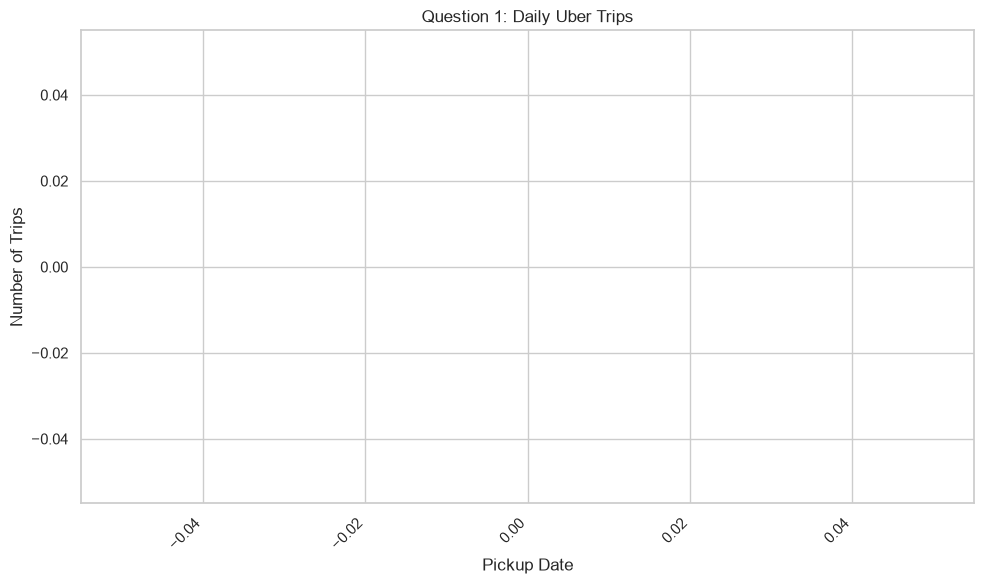

In [18]:
# Extract the calendar date from each pickup timestamp
trips_analysis["Pickup Date"] = trips_analysis["Pickup Time"].dt.date

# Count unique trips for each date
daily_trips = (
    trips_analysis.groupby("Pickup Date")["Trip ID"]
    .nunique()
    .sort_index()
)

# Display daily trip counts
display(daily_trips.rename("Total Trips").reset_index())

# Plot daily trip demand over time
daily_trips.plot(kind="line", marker="o", markersize=3)
plt.title("Question 1: Daily Uber Trips")
plt.xlabel("Pickup Date")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Question 2: Which hours of the day have the highest trip demand?

**Why are we running this code?**

To identify peak hours and quieter periods, helping us understand when Uber services are used most frequently.

,Pickup Hour,Total Trips
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0
5,5,0
6,6,0
7,7,0
8,8,0
9,9,0


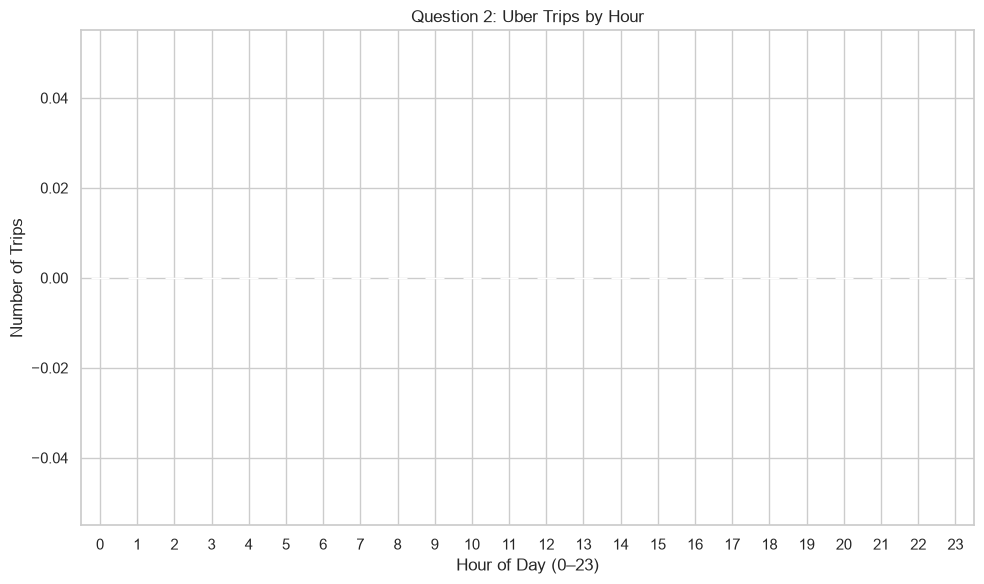

In [19]:
# Extract the pickup hour from each trip
trips_analysis["Pickup Hour"] = trips_analysis["Pickup Time"].dt.hour

# Count unique trips for each hour
hourly_trips = (
    trips_analysis.groupby("Pickup Hour")["Trip ID"]
    .nunique()
    .reindex(range(24), fill_value=0)
)

# Display trip counts for all 24 hours
display(hourly_trips.rename("Total Trips").reset_index())

# Plot hourly trip demand
hourly_trips.plot(kind="bar", color="steelblue")
plt.title("Question 2: Uber Trips by Hour")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Number of Trips")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Question 3: Which days of the week have the highest trip demand?

**Why are we running this code?**

To compare trip demand across weekdays and weekends and identify the days with the most activity.

,Weekday,Total Trips
0,Monday,0
1,Tuesday,0
2,Wednesday,0
3,Thursday,0
4,Friday,0
5,Saturday,0
6,Sunday,0


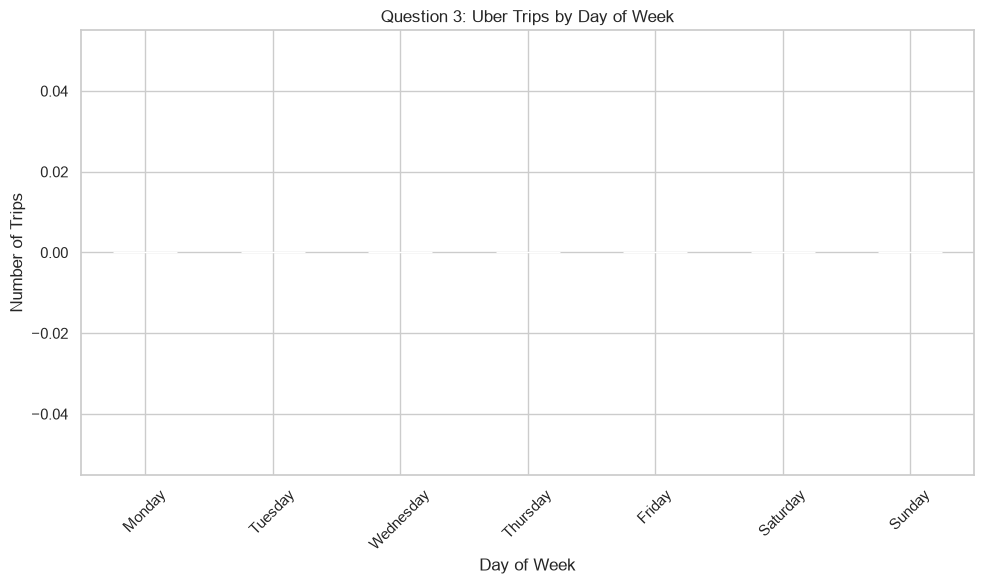

In [21]:
# Extract the weekday name from each pickup timestamp
trips_analysis["Weekday"] = trips_analysis["Pickup Time"].dt.day_name()

# Define the correct weekday order for comparison
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Count unique trips for each weekday
weekday_trips = (
    trips_analysis.groupby("Weekday")["Trip ID"]
    .nunique()
    .reindex(weekday_order, fill_value=0)
)

# Display trip counts by weekday
display(weekday_trips.rename("Total Trips").reset_index())

# Plot weekday trip demand
weekday_trips.plot(kind="bar", color="teal")
plt.title("Question 3: Uber Trips by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Question 4: How does trip demand change from month to month?

**Why are we running this code?**

To identify monthly demand patterns and understand whether trip activity increases or decreases over time.

Valid Pickup Times: 103728


,Pickup Time,Total Trips
0,2024-06,103728


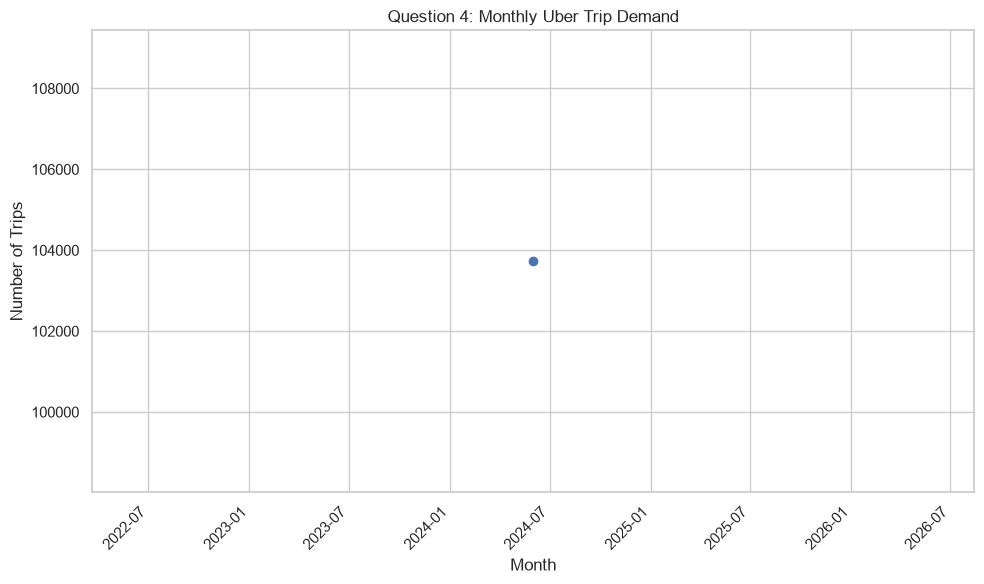

In [26]:
# Import the required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Uber trip dataset
trips = pd.read_csv(
    r"C:\Users\M.SANTHOSH\Downloads\Uber Trip Details.csv"
)

# Load the location dataset
locations = pd.read_csv(
    r"C:\Users\M.SANTHOSH\Downloads\Location Table.csv"
)

# Create a copy of the trip dataset for analysis
trips_analysis = trips.copy()

# Replace the dot in the time portion with a colon
# Example: 01-06-2024 0.42 becomes 01-06-2024 0:42
trips_analysis["Pickup Time"] = (
    trips_analysis["Pickup Time"]
    .astype("string")
    .str.replace(r"(\d{1,2})\.(\d{2})$", r"\1:\2", regex=True)
)

# Convert pickup times using the day-month-year format
trips_analysis["Pickup Time"] = pd.to_datetime(
    trips_analysis["Pickup Time"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

# Display the number of valid timestamps after conversion
print(
    "Valid Pickup Times:",
    trips_analysis["Pickup Time"].notna().sum()
)

# Exclude records with invalid pickup times from this analysis
valid_trips = trips_analysis.dropna(
    subset=["Pickup Time"]
).copy()

# Group trips by month and count unique trip IDs
monthly_trips = (
    valid_trips.groupby(
        valid_trips["Pickup Time"].dt.to_period("M")
    )["Trip ID"]
    .nunique()
    .sort_index()
)

# Display the monthly trip counts
display(
    monthly_trips.rename("Total Trips").reset_index()
)

# Plot monthly demand when valid data is available
if not monthly_trips.empty:
    # Convert monthly periods into dates for plotting
    monthly_trips.index = monthly_trips.index.to_timestamp()

    # Create a line chart to compare monthly trip demand
    monthly_trips.plot(kind="line", marker="o")

    # Add chart title and axis labels
    plt.title("Question 4: Monthly Uber Trip Demand")
    plt.xlabel("Month")
    plt.ylabel("Number of Trips")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    # Display a message if timestamps could not be converted
    print("No valid pickup timestamps found. Check the date format.")

# Question 5: Which cities generate the most pickup trips?

**Why are we running this code?**

To identify the cities with the highest pickup activity and understand where trip demand is concentrated geographically.

,City,Total Trips
0,Manhattan,64038
1,Queens,16888
2,Brooklyn,16351
3,The Bronx,4693
4,Staten Island,652
5,Bronx,179
6,"Newark, New Jersey",1


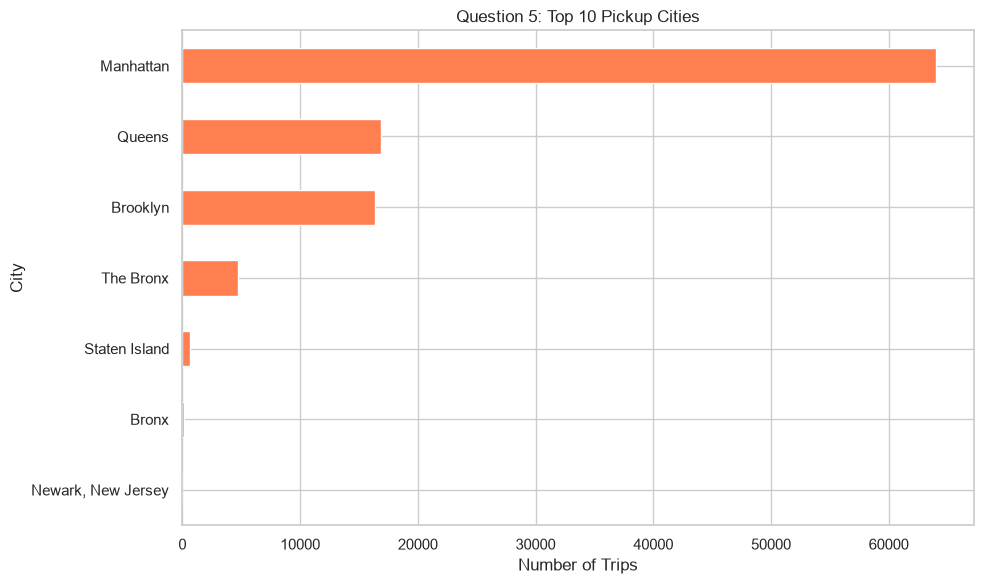

In [27]:
# Match pickup location IDs with the location dataset to obtain city names
pickup_city_data = trips_analysis.merge(
    locations_analysis[["LocationID", "City"]],
    left_on="PULocationID",
    right_on="LocationID",
    how="left"
)

# Count unique trips for each pickup city
city_trips = (
    pickup_city_data.groupby("City")["Trip ID"]
    .nunique()
    .sort_values(ascending=False)
)

# Display trip counts by pickup city
display(city_trips.rename("Total Trips").reset_index())

# Plot the top 10 cities by pickup trip volume
city_trips.head(10).sort_values().plot(kind="barh", color="coral")
plt.title("Question 5: Top 10 Pickup Cities")
plt.xlabel("Number of Trips")
plt.ylabel("City")
plt.tight_layout()
plt.show()

# Question 6: What is the average fare for each payment method?

**Why are we running this code?**

To compare average fares across payment methods and identify differences in the typical fare value of trips paid through each method.

,Payment_type,Average Fare
0,Google Pay,15.11
1,Amazon Pay,14.65
2,Cash,13.26
3,Uber Pay,12.85


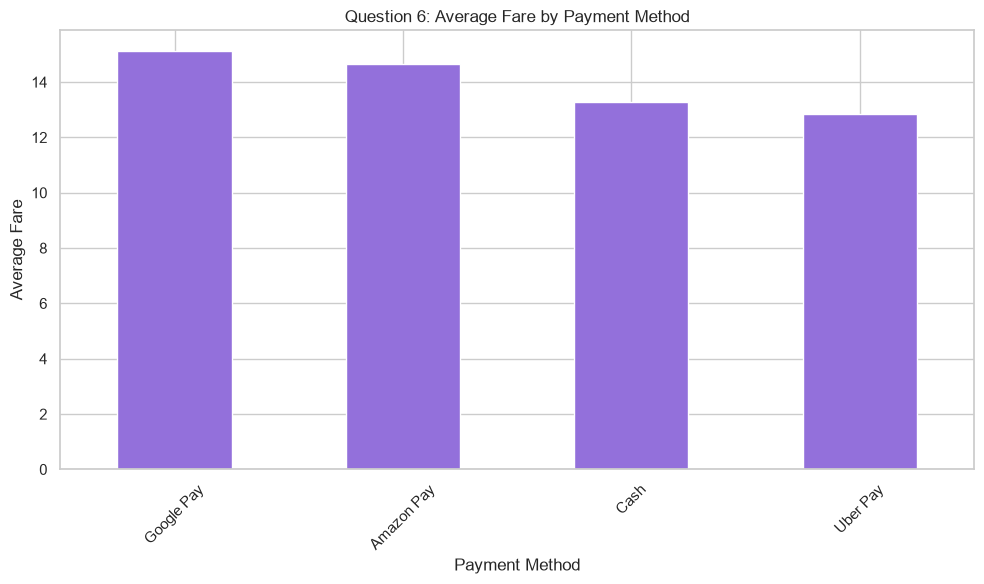

In [28]:
# Group trips by payment method and calculate the average fare
average_fare_by_payment = (
    trips_analysis.groupby("Payment_type")["fare_amount"]
    .mean()
    .sort_values(ascending=False)
)

# Display average fare by payment method
display(
    average_fare_by_payment
    .round(2)
    .rename("Average Fare")
    .reset_index()
)

# Plot average fare by payment method
average_fare_by_payment.plot(kind="bar", color="mediumpurple")
plt.title("Question 6: Average Fare by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Average Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Question 7: How do trips with surge fees compare with trips without surge fees?

**Why are we running this code?**

To compare trip volume and average fare between trips with a positive surge fee and trips without one.

,Total_Trips,Average_Fare
Surge Status,,
With Surge,65926,12.71
Without Surge,37802,13.50


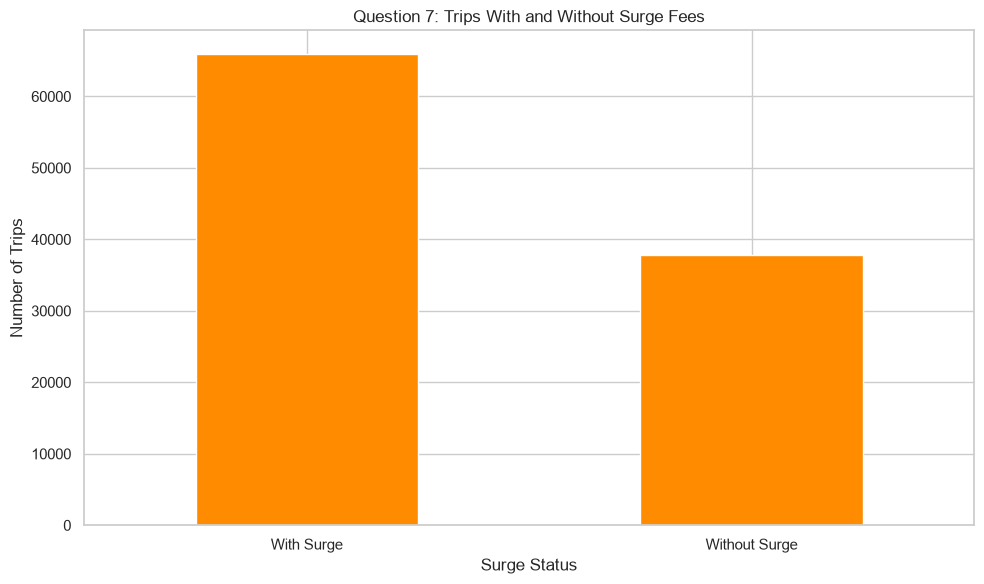

In [29]:
# Classify trips according to whether a positive surge fee was recorded
trips_analysis["Surge Status"] = np.where(
    trips_analysis["Surge Fee"] > 0,
    "With Surge",
    "Without Surge"
)

# Calculate trip counts and average fares for each surge category
surge_comparison = (
    trips_analysis.groupby("Surge Status")
    .agg(
        Total_Trips=("Trip ID", "nunique"),
        Average_Fare=("fare_amount", "mean")
    )
    .round(2)
)

# Display the surge and non-surge comparison
display(surge_comparison)

# Plot trip counts by surge category
surge_comparison["Total_Trips"].plot(kind="bar", color="darkorange")
plt.title("Question 7: Trips With and Without Surge Fees")
plt.xlabel("Surge Status")
plt.ylabel("Number of Trips")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Question 8: Which vehicle types have the highest average trip distance?

**Why are we running this code?**

To compare average trip distances across vehicle types and understand how travel patterns differ by vehicle category.

,Vehicle,Average Trip Distance
0,UberX,3.39
1,Uber Green,3.36
2,Uber Black,3.36
3,UberXL,3.34
4,Uber Comfort,3.33


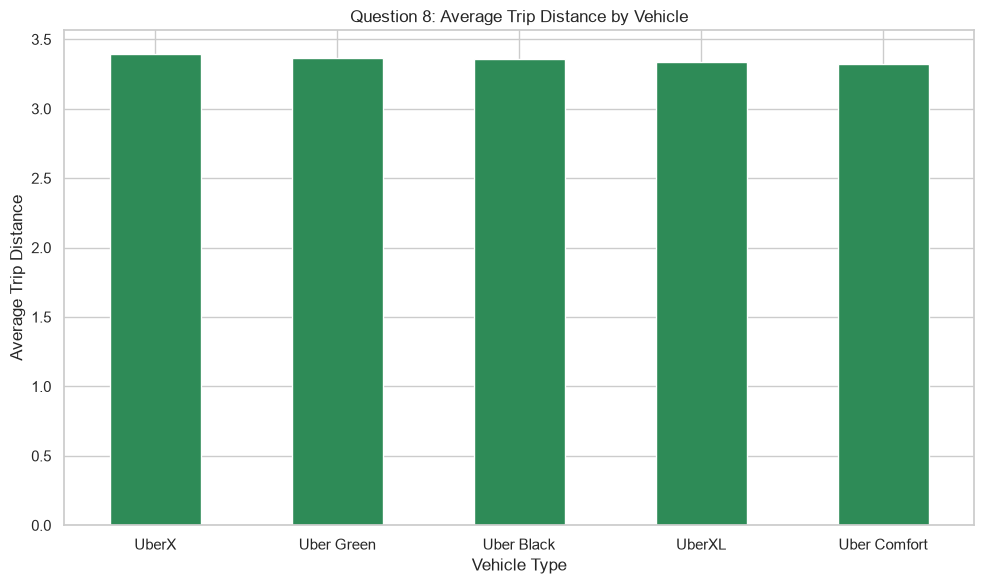

In [30]:
# Group trips by vehicle type and calculate the average trip distance
average_distance_by_vehicle = (
    trips_analysis.groupby("Vehicle")["trip_distance"]
    .mean()
    .sort_values(ascending=False)
)

# Display average trip distance by vehicle type
display(
    average_distance_by_vehicle
    .round(2)
    .rename("Average Trip Distance")
    .reset_index()
)

# Plot average distance by vehicle type
average_distance_by_vehicle.plot(kind="bar", color="seagreen")
plt.title("Question 8: Average Trip Distance by Vehicle")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Trip Distance")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Question 9: What are the most popular pickup and drop-off routes?

**Why are we running this code?**

To identify the most frequently travelled routes and understand which pickup-to-drop-off combinations have the highest demand.


,Pickup Location,Drop-off Location,Total Trips
0,NV,NV,487
1,East Harlem South,East Harlem North,412
2,Upper East Side South,Upper East Side North,395
3,Upper East Side North,Upper East Side South,352
4,Lenox Hill East,Upper East Side North,283
5,Upper East Side North,Midtown East,282
6,Upper East Side North,Lenox Hill East,277
7,Penn Station/Madison Sq West,Midtown Center,274
8,Lincoln Square East,Upper West Side North,260
9,Yorkville West,Lenox Hill East,244


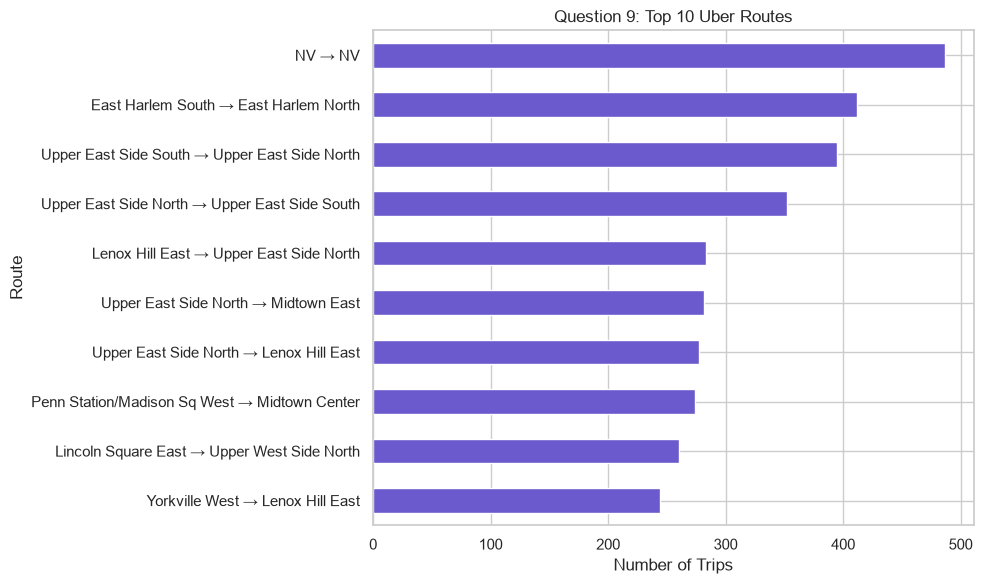

In [31]:
# Match pickup IDs with location names
route_data = trips_analysis.merge(
    locations_analysis[["LocationID", "Location"]],
    left_on="PULocationID",
    right_on="LocationID",
    how="left"
).rename(columns={"Location": "Pickup Location"})

# Match drop-off IDs with location names
route_data = route_data.merge(
    locations_analysis[["LocationID", "Location"]],
    left_on="DOLocationID",
    right_on="LocationID",
    how="left"
).rename(columns={"Location": "Drop-off Location"})

# Count unique trips for each pickup and drop-off combination
top_routes = (
    route_data.groupby(["Pickup Location", "Drop-off Location"])["Trip ID"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

# Display the top 10 routes
display(top_routes.rename("Total Trips").reset_index())

# Create readable route labels for the chart
route_labels = top_routes.copy()
route_labels.index = [
    f"{pickup} → {dropoff}"
    for pickup, dropoff in route_labels.index
]

# Plot the top 10 routes
route_labels.sort_values().plot(kind="barh", color="slateblue")
plt.title("Question 9: Top 10 Uber Routes")
plt.xlabel("Number of Trips")
plt.ylabel("Route")
plt.tight_layout()
plt.show()

# Question 10: How does total fare revenue change from month to month?

**Why are we running this code?**

To track monthly fare revenue and identify periods when revenue rises or falls. This helps compare revenue trends with monthly trip demand.

,Revenue Month,Total Fare Revenue
0,2024-06,1348291.45


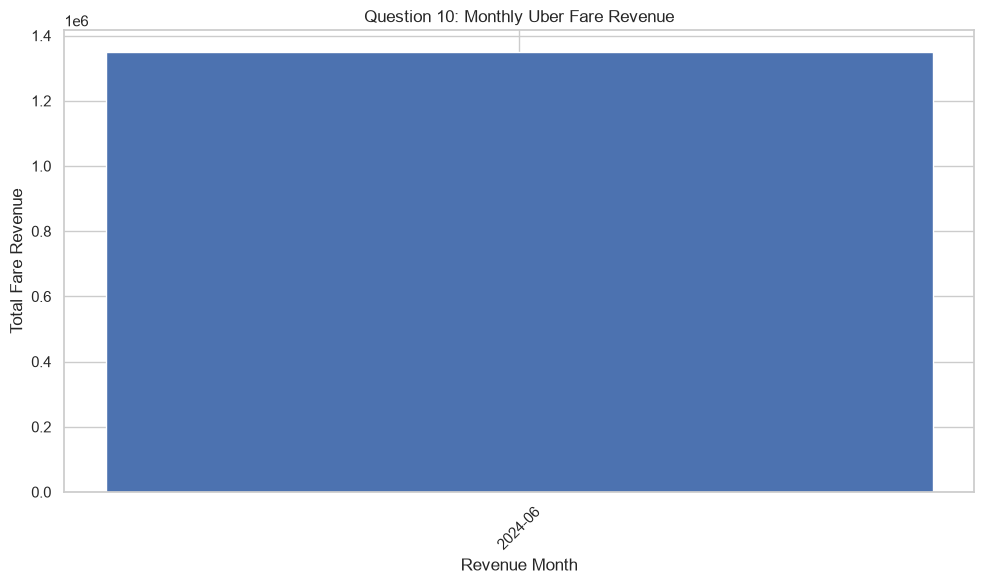

In [33]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set the chart style
sns.set_theme(style="whitegrid")

# Set the default chart size
plt.rcParams["figure.figsize"] = (10, 6)

# Load the Uber trip dataset
trips = pd.read_csv(
    r"C:\Users\M.SANTHOSH\Downloads\Uber Trip Details.csv"
)

# Load the location dataset
locations = pd.read_csv(
    r"C:\Users\M.SANTHOSH\Downloads\Location Table.csv"
)

# Create copies of the datasets for analysis
trips_analysis = trips.copy()
locations_analysis = locations.copy()

# Correct the dot separator in pickup times
# Example: 01-06-2024 0.42 becomes 01-06-2024 0:42
trips_analysis["Pickup Time"] = (
    trips_analysis["Pickup Time"]
    .astype("string")
    .str.replace(r"(\d{1,2})\.(\d{2})$", r"\1:\2", regex=True)
)

# Convert pickup times into datetime format
trips_analysis["Pickup Time"] = pd.to_datetime(
    trips_analysis["Pickup Time"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

# Convert fare amounts into numeric values
trips_analysis["fare_amount"] = pd.to_numeric(
    trips_analysis["fare_amount"],
    errors="coerce"
)

# Remove rows with invalid pickup times or missing fare amounts
valid_trips = trips_analysis.dropna(
    subset=["Pickup Time", "fare_amount"]
).copy()

# Extract the year and month from each pickup timestamp
valid_trips["Revenue Month"] = (
    valid_trips["Pickup Time"].dt.to_period("M")
)

# Group trips by month and calculate total fare revenue
monthly_revenue = (
    valid_trips.groupby("Revenue Month")["fare_amount"]
    .sum()
    .sort_index()
)

# Convert the monthly revenue results into a table
monthly_revenue_table = monthly_revenue.reset_index(
    name="Total Fare Revenue"
)

# Display the monthly fare revenue table
display(monthly_revenue_table)

# Check whether monthly revenue data is available
if not monthly_revenue.empty:

    # Convert month periods into readable labels
    month_labels = monthly_revenue.index.astype(str)

    # Create a bar chart for monthly fare revenue
    plt.figure(figsize=(10, 6))
    plt.bar(month_labels, monthly_revenue.values)

    # Add the chart title and axis labels
    plt.title("Question 10: Monthly Uber Fare Revenue")
    plt.xlabel("Revenue Month")
    plt.ylabel("Total Fare Revenue")

    # Rotate month labels for better readability
    plt.xticks(rotation=45)

    # Adjust the chart layout
    plt.tight_layout()

    # Display the chart
    plt.show()

else:
    # Display a message if no valid revenue data is available
    print("No valid monthly fare revenue data found.")
    